In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

train = pd.read_csv("train.csv")
val = pd.read_csv("val.csv")
test = pd.read_csv("test.csv")

X_train = train[["x1", "x2"]].to_numpy()
y_train = train["y"].to_numpy()

X_val = val[["x1", "x2"]].to_numpy()
y_val = val["y"].to_numpy()

X_test = test[["x1", "x2"]].to_numpy()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (600, 2)
Validation: (200, 2)
Test: (200, 2)


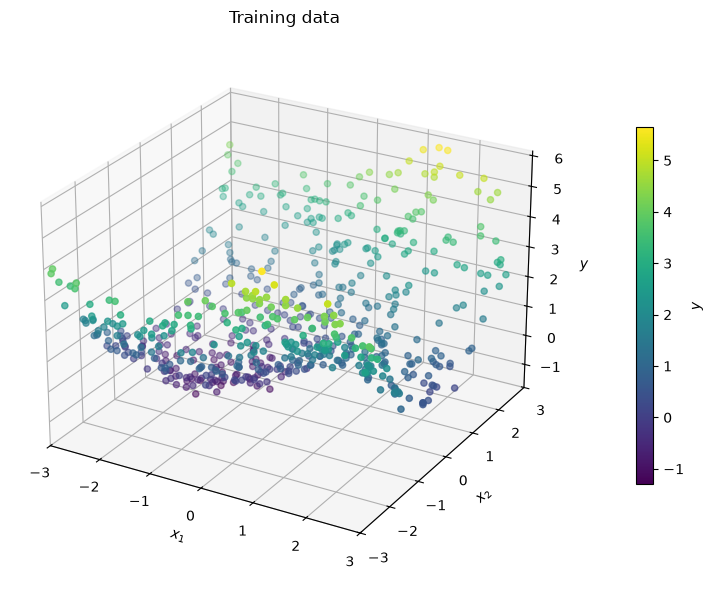

In [3]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

points = ax.scatter(
    X_train[:, 0],
    X_train[:, 1],
    y_train,
    c=y_train,
    cmap="viridis",
    s=20,
)

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$y$")
ax.set_title("Training data")
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.view_init(elev=25, azim=-60)

fig.colorbar(points, ax=ax, label="$y$", shrink=0.65, pad=0.1)

fig.tight_layout()
fig.savefig("problem3_training_data.png", dpi=300)
plt.show()

In [ ]:
class RandomKitchenSinks:
    def __init__(
        self,
        D: int = 1000,
        sigma: float = 1.0,
        ridge_lambda: float = 1e-3,
    ):
        if D <= 0 or D % 2 != 0:
            raise ValueError("D must be a positive even integer.")

        self.D = D
        self.ridge_lambda = ridge_lambda

        rng = np.random.default_rng(42)
        h = D // 2

        self.W = rng.normal(
            loc=0.0, scale=1.0 / sigma, size=(h, 2)
        )
        self.b = rng.uniform(0.0, 2 * np.pi, size=h)

    def _features(self, X: np.ndarray) -> np.ndarray:
        projection = X @ self.W.T + self.b

        phi = np.stack(
            [np.sin(projection), np.cos(projection)],
            axis=2,
        ).reshape(len(X), self.D)

        return np.column_stack([np.ones(len(X)), phi])

    def fit(self, X: np.ndarray, y: np.ndarray):
        phi = self._features(X)

        penalty = self.ridge_lambda * np.eye(phi.shape[1])
        penalty[0, 0] = 0.0 

        self.coef_ = np.linalg.solve(
            phi.T @ phi + penalty,
            phi.T @ y,
        )
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        phi = self._features(X)
        return phi @ self.coef_

In [ ]:
from typing import List, Tuple

def sweep_rks_model(
    sweep_D: List[int],
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
) -> Tuple:
    best_model = None
    best_val_mse = float("inf")
    best_D = None
    results = []

    for D in sweep_D:
        model = RandomKitchenSinks(D=D)
        model.fit(X_train, y_train)

        train_mse = np.mean(
            (y_train - model.predict(X_train)) ** 2
        )
        val_mse = np.mean(
            (y_val - model.predict(X_val)) ** 2
        )

        results.append({
            "D": D,
            "Train MSE": train_mse,
            "Validation MSE": val_mse,
        })

        if val_mse < best_val_mse:
            best_model = model
            best_val_mse = val_mse
            best_D = D

    best_model.sweep_results_ = results
    return best_model, best_val_mse, best_D

  D  Train MSE  Validation MSE  h
 20   0.035597        0.036619 10
 30   0.033271        0.035899 15
 40   0.032430        0.036658 20
 50   0.032011        0.036996 25
 60   0.031688        0.037228 30
 70   0.031576        0.037298 35
 80   0.031520        0.037156 40
 90   0.031422        0.037472 45
100   0.031138        0.037911 50
110   0.030856        0.038565 55
120   0.030675        0.038549 60
130   0.030544        0.038259 65
140   0.030461        0.038578 70

Selected h: 15
Best validation MSE: 0.035898624144402855


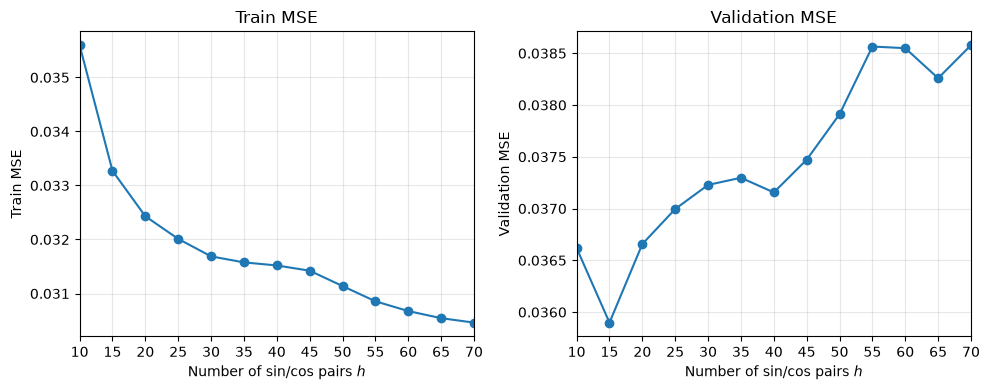

In [23]:
sweep_h = list(range(10, 71, 5))
sweep_D = [2 * h for h in sweep_h]

best_rks, best_rks_val_mse, best_rks_D = sweep_rks_model(
    sweep_D, X_train, y_train, X_val, y_val
)

rks_results = pd.DataFrame(best_rks.sweep_results_)
rks_results["h"] = rks_results["D"] // 2

print(rks_results.to_string(index=False))
print("\nSelected h:", best_rks_D // 2)
print("Best validation MSE:", best_rks_val_mse)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, metric in zip(
    axes, ["Train MSE", "Validation MSE"]
):
    ax.plot(rks_results["h"], rks_results[metric], marker="o")
    ax.set_xlim(10, 70)
    ax.set_xticks(sweep_h)
    ax.set_xlabel("Number of sin/cos pairs $h$")
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("problem3_rks_sweep.png", dpi=300)
plt.show()

In [24]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


class MLP(nn.Module):
    def __init__(
        self,
        d_in: int,
        d_hidden: int = 128,
        d_out: int = 1,
        lr: float = 1e-3,
        batch_size: int = 128,
        activation: str = "relu",
        device: str = "cpu",
        num_epochs: int = 1000,
    ):
        super().__init__()

        self.device = device
        self.lr = lr
        self.batch_size = batch_size
        self.num_epochs = num_epochs

        if activation == "relu":
            activation_fn = nn.ReLU()
        elif activation == "tanh":
            activation_fn = nn.Tanh()
        else:
            raise ValueError("Unsupported activation.")

        self.net = nn.Sequential(
            nn.Linear(d_in, d_hidden),
            activation_fn,
            nn.Linear(d_hidden, d_out),
        ).to(self.device)

    def fit(self, X: np.ndarray, y: np.ndarray):
        X = torch.from_numpy(X).float()
        y = torch.from_numpy(y).float().view(-1, 1)

        loader = DataLoader(
            TensorDataset(X, y),
            batch_size=self.batch_size,
            shuffle=True,
        )

        optimizer = torch.optim.Adam(
            self.net.parameters(), lr=self.lr
        )
        loss_fn = nn.MSELoss()

        self.net.train()

        for epoch in range(self.num_epochs):
            for xb, yb in loader:
                xb = xb.to(self.device)
                yb = yb.to(self.device)

                optimizer.zero_grad()
                loss = loss_fn(self.forward(xb), yb)
                loss.backward()
                optimizer.step()

        return self

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        return self.net(X)

    def predict(self, X: np.ndarray) -> np.ndarray:
        self.net.eval()

        with torch.no_grad():
            X = torch.from_numpy(X).float().to(self.device)
            return self.forward(X).cpu().numpy()

In [ ]:
def mlp_sweep(
    sweep_values: List[int],
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
) -> Tuple:
    best_model = None
    best_val_mse = float("inf")
    best_hidden = None
    results = []

    for hidden in sweep_values:
        torch.manual_seed(SEED)

        model = MLP(
            d_in=X_train.shape[1],
            d_hidden=hidden,
        )
        model.fit(X_train, y_train)

        train_pred = model.predict(X_train).ravel()
        val_pred = model.predict(X_val).ravel()

        train_mse = np.mean((y_train - train_pred) ** 2)
        val_mse = np.mean((y_val - val_pred) ** 2)

        results.append({
            "Hidden dimension": hidden,
            "Train MSE": train_mse,
            "Validation MSE": val_mse,
        })

        if val_mse < best_val_mse:
            best_model = model
            best_val_mse = val_mse
            best_hidden = hidden

    best_model.sweep_results_ = results
    return best_model, best_val_mse, best_hidden

In [30]:
sweep_hidden = [16, 32, 64, 128, 256, 512, 1024, 2048]

best_mlp, best_mlp_val_mse, best_mlp_hidden = mlp_sweep(
    sweep_hidden,
    X_train,
    y_train,
    X_val,
    y_val,
)

mlp_results = pd.DataFrame(best_mlp.sweep_results_)

print(mlp_results.to_string(index=False))
print("\nSelected hidden dimension:", best_mlp_hidden)
print("Best validation MSE:", best_mlp_val_mse)

 Hidden dimension  Train MSE  Validation MSE
               16   0.043929        0.048891
               32   0.034419        0.043511
               64   0.030986        0.039897
              128   0.029739        0.039227
              256   0.028713        0.039536
              512   0.027212        0.039189
             1024   0.026814        0.041448
             2048   0.031189        0.044642

Selected hidden dimension: 512
Best validation MSE: 0.0391891351299394


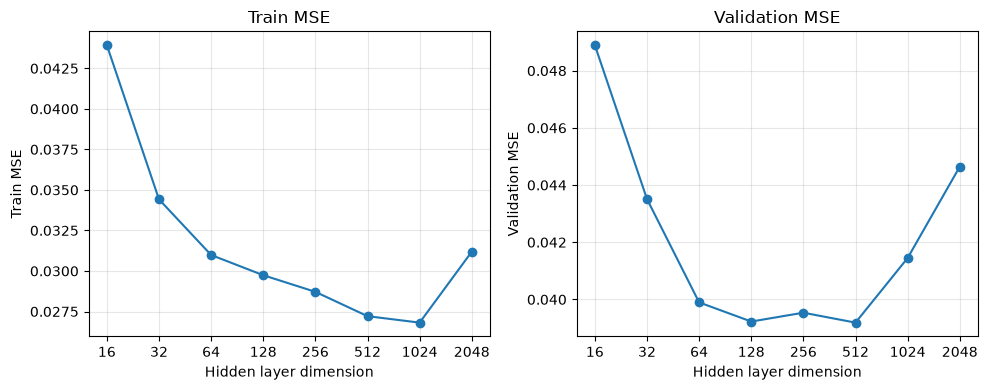

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, metric in zip(
    axes, ["Train MSE", "Validation MSE"]
):
    ax.plot(
        mlp_results["Hidden dimension"],
        mlp_results[metric],
        marker="o",
    )
    ax.set_xscale("log", base=2)
    ax.set_xticks(sweep_hidden)
    ax.set_xticklabels(sweep_hidden)
    ax.set_xlabel("Hidden layer dimension")
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("problem3_mlp_sweep.png", dpi=300)
plt.show()

In [ ]:
rks_final = RandomKitchenSinks(D=best_rks_D)
rks_final.fit(X_train, y_train)

torch.manual_seed(SEED)

mlp_final = MLP(
    d_in=2,
    d_hidden=best_mlp_hidden,
)
mlp_final.fit(X_train, y_train)

rks_val_mse = np.mean(
    (y_val - rks_final.predict(X_val)) ** 2
)
mlp_val_mse = np.mean(
    (y_val - mlp_final.predict(X_val).ravel()) ** 2
)

comparison = pd.DataFrame({
    "Model": ["RKS", "One-hidden-layer MLP"],
    "Validation MSE": [rks_val_mse, mlp_val_mse],
})

comparison

,Model,Validation MSE
0,RKS,0.035899
1,One-hidden-layer MLP,0.039189


In [33]:
rks_test_pred = rks_final.predict(X_test).ravel()
mlp_test_pred = mlp_final.predict(X_test).ravel()

np.savetxt(
    "rks_test_predictions.csv",
    rks_test_pred,
    delimiter=",",
)
np.savetxt(
    "mlp_test_predictions.csv",
    mlp_test_pred,
    delimiter=",",
)

print("Predictions saved:", len(rks_test_pred), len(mlp_test_pred))

Predictions saved: 200 200


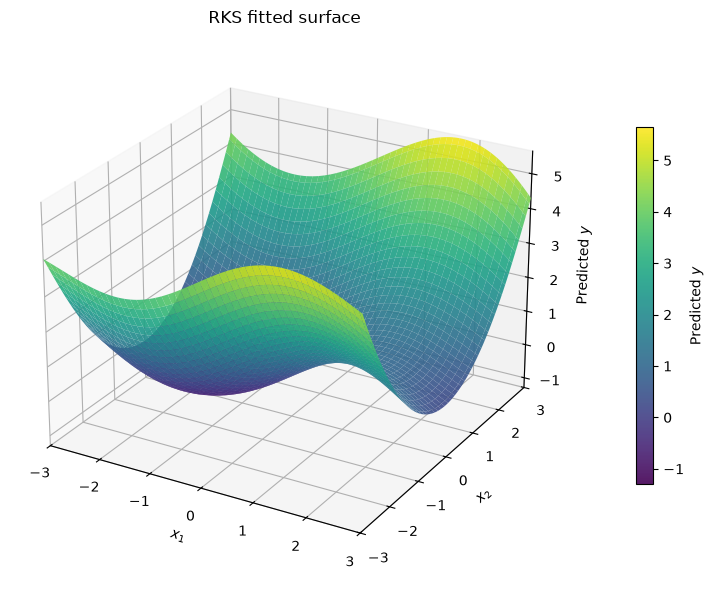

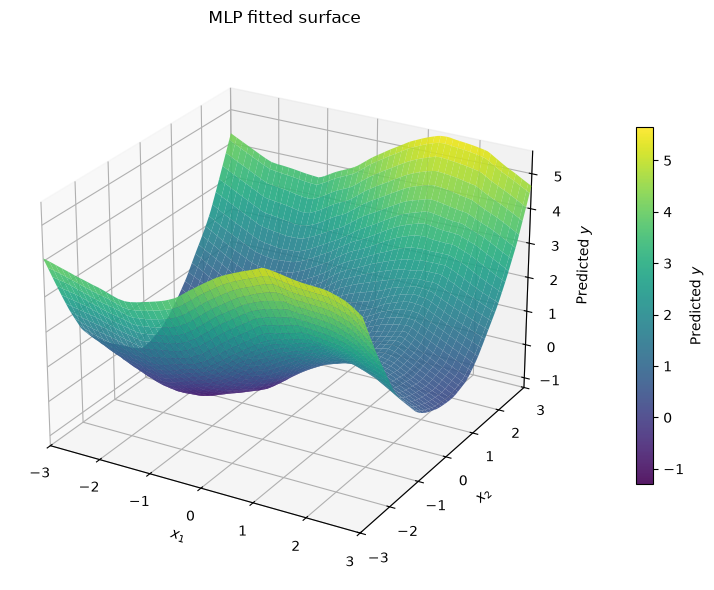

In [36]:
grid = np.linspace(-3, 3, 100)
X1, X2 = np.meshgrid(grid, grid)
X_grid = np.column_stack([X1.ravel(), X2.ravel()])

Z_rks = rks_final.predict(X_grid).reshape(X1.shape)
Z_mlp = mlp_final.predict(X_grid).reshape(X1.shape)

z_min = min(y_train.min(), Z_rks.min(), Z_mlp.min())
z_max = max(y_train.max(), Z_rks.max(), Z_mlp.max())

for name, Z, filename in [
    ("RKS", Z_rks, "3_d_rks.png"),
    ("MLP", Z_mlp, "3_d_mlp.png"),
]:
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    surface = ax.plot_surface(
        X1, X2, Z,
        cmap="viridis",
        vmin=z_min,
        vmax=z_max,
        alpha=0.9,
    )

    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_zlabel("Predicted $y$")
    ax.set_title(f"{name} fitted surface")
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_zlim(z_min, z_max)
    ax.view_init(elev=25, azim=-60)

    fig.colorbar(
        surface, ax=ax,
        label="Predicted $y$",
        shrink=0.65, pad=0.1,
    )

    fig.tight_layout()
    fig.savefig(filename, dpi=300)
    plt.show()